# ESA / UHF telemetry review — data selection for the anomaly-detection model

Read-only screening of the Zenodo **ESA Anomaly Dataset** (anonymized satellite telemetry) and the OPS-SAT **UHF** export. This notebook decides which real telemetry streams the anomaly-detection model will be built on, and which streams are kept for the replay / mock-sensor pipeline.

**Scope**

- Explores catalogs, channel statistics, and annotation coverage only.
- Does **not** train a model, generate synthetic data, or modify the source archives.
- Treats every ESA channel as an **anonymized, unknown-signal** stream. `Channel`, `Subsystem`, and `Physical Unit` values are placeholders, so no ESA channel is claimed to be a named physical sensor.

**Two separate data purposes — keep them apart**

| Purpose | Data | Used for |
| --- | --- | --- |
| Anomaly-detection model | Real ESA channels **with** annotations (selected in Part C) | Feature engineering, training, evaluation |
| Streaming / mock sensors | Replay of real streams + PR#2-generated values | MQTT streaming, fault injection, FSM testing |

Generated/mock values are **never** used to train or evaluate the model. Physical Raspberry Pi sensor readings are used to verify fault injection and recovery behaviour only.

Keep source datasets and extracted copies outside the repository.


## How this notebook is organised

| Part | What it establishes |
| --- | --- |
| **A** | UHF reference telemetry — named, but sparse; usable as a streaming reference, not as a model dataset |
| **B1** | Zenodo archive metadata and catalog access (no full download required) |
| **B2** | Candidate screening — which anonymized channels are continuous, grouped, and annotated |
| **B3** | Channel-level profiling — volume, cadence, range, annotation coverage, labelled vs unlabelled behaviour |
| **B4** | Group-level checks — intra-group correlation and shared label windows |
| **C** | Final data selection, exclusions, handling rules, and the reasoning behind them |

Run order matters: later cells reuse objects from earlier ones (`all_channels`, `label_details`, `read_remote_channel`, `make_sample_mask`, `series`, `events`).

**Reading tip.** Most tables are *screening evidence*, not results. The decisions are in Part C; everything before it exists to justify or reject a candidate.


## Part A — UHF reference telemetry

### A1. Colab setup

`uhf_telemetry.csv` is the OPS-SAT UHF export. Upload it to Colab or mount Drive and set `UHF_CSV_PATH`.

UHF is examined first because its channels have **real names** (`NanoMind_Temp`, `Battery_Voltage`, `X/Y/Z_Coarse_Spin`). That makes it a useful semantic reference for the streaming side — it shows how a temperature-like, voltage-like, or spin-like signal is expected to look. It is **not** the model dataset: coverage is only ~4–5% of rows and the records are asynchronous.

The Zenodo section below only queries metadata; it does not download the dataset.


In [2]:
from pathlib import Path
import csv, io, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

# Optional Drive setup:
# from google.colab import drive
# drive.mount('/content/drive')
UHF_CSV_PATH = '/content/uhf_telemetry.csv'  # edit if using Drive
ZENODO_RECORD_ID = '15237121'
ZENODO_API_URL = f'https://zenodo.org/api/records/{ZENODO_RECORD_ID}'
TIMESTAMP_COLUMN = 'Timestamp'
REFERENCE_COLUMNS = ['NanoMind_Temp', 'Battery_Voltage', 'X_Coarse_Spin', 'Y_Coarse_Spin', 'Z_Coarse_Spin']
if not Path(UHF_CSV_PATH).is_file():
    raise FileNotFoundError(f'Upload the UHF CSV or update UHF_CSV_PATH: {UHF_CSV_PATH}')
print('Ready:', UHF_CSV_PATH)

Ready: /content/uhf_telemetry.csv


### A2. UHF schema and reference-channel quality

This export contains asynchronous/sparse rows. We keep each channel's actual timestamps and do not forward-fill or interpolate missing values. Zeros are reported separately, not assumed to mean missing.

What to look for: non-null count and coverage per channel (how much of the export actually carries that signal), value range, zero rate, and the gap distribution.

Expected shape: 16,500 rows, 22 columns, coverage around 4.0–4.6% for the reference channels, and maximum gaps of days. That sparsity is the reason UHF cannot serve as the model's training data.


In [3]:
columns = pd.read_csv(UHF_CSV_PATH, nrows=0).columns.tolist()
print(f'Columns ({len(columns)}):', columns)
missing = [c for c in [TIMESTAMP_COLUMN, *REFERENCE_COLUMNS] if c not in columns]
if missing:
    raise ValueError(f'Reference column(s) not found: {missing}')
uhf = pd.read_csv(UHF_CSV_PATH, usecols=[TIMESTAMP_COLUMN, *REFERENCE_COLUMNS])
uhf[TIMESTAMP_COLUMN] = pd.to_datetime(uhf[TIMESTAMP_COLUMN], errors='coerce')
for c in REFERENCE_COLUMNS:
    uhf[c] = pd.to_numeric(uhf[c], errors='coerce')
print(f'Rows: {len(uhf):,}; invalid timestamps: {uhf[TIMESTAMP_COLUMN].isna().sum():,}')
print(f'Duplicate timestamps: {uhf[TIMESTAMP_COLUMN].duplicated().sum():,}')
print(f'Rows out of timestamp order: {(uhf[TIMESTAMP_COLUMN].diff().dropna() < pd.Timedelta(0)).sum():,}')
uhf.head()

Columns (22): ['Timestamp', 'ADCS_mode', 'X_Coarse_Spin', 'Y_Coarse_Spin', 'Z_Coarse_Spin', 'PD1_CSS_theta', 'PD2_CSS_theta', 'PD3_CSS_theta', 'PD4_CSS_theta', 'PD5_CSS_theta', 'PD6_CSS_theta', 'HD_Cam_Temp', 'ACU2_Temp', 'Battery_Temp', 'Battery_Voltage', 'NanoMind_Temp', 'PDU_Channels_Status', 'SDR_Temp', 'SEPP_Temp', 'Background_RSSI', 'Last_RSSI', 'NanoCom_Temp']
Rows: 16,500; invalid timestamps: 0
Duplicate timestamps: 2
Rows out of timestamp order: 1,668


,Timestamp,X_Coarse_Spin,Y_Coarse_Spin,Z_Coarse_Spin,Battery_Voltage,NanoMind_Temp
0,2024-05-01 04:57:03.720,NaN,NaN,NaN,NaN,NaN
1,2024-05-01 04:57:10.000,NaN,NaN,NaN,NaN,NaN
2,2024-05-01 04:57:18.111,NaN,NaN,NaN,NaN,NaN
3,2024-05-01 04:57:22.000,NaN,NaN,NaN,NaN,NaN
4,2024-05-01 04:57:32.000,NaN,NaN,NaN,NaN,NaN


In [4]:
def summarize_channel(frame, col):
    d = frame[[TIMESTAMP_COLUMN, col]].dropna().sort_values(TIMESTAMP_COLUMN)
    x, t = d[col], d[TIMESTAMP_COLUMN]
    gaps = t.diff().dt.total_seconds().dropna()
    return {'channel': col, 'non_null': len(x),
            'coverage_pct': round(100 * frame[col].notna().mean(), 2),
            'unique': int(x.nunique()),
            'zero_pct_present': round(100 * x.eq(0).mean(), 2) if len(x) else np.nan,
            'min': x.min(), 'p01': x.quantile(.01), 'median': x.median(),
            'p99': x.quantile(.99), 'max': x.max(),
            'median_gap_s': gaps.median() if len(gaps) else np.nan,
            'max_gap_s': gaps.max() if len(gaps) else np.nan}
summary = pd.DataFrame([summarize_channel(uhf, c) for c in REFERENCE_COLUMNS])
display(summary)

,channel,non_null,coverage_pct,unique,zero_pct_present,min,p01,median,p99,max,median_gap_s,max_gap_s
0,NanoMind_Temp,665,4.03,182,0.00,219.000000,223.640000,330.000000,433.000000,448.000000,20.009,30579.992
1,Battery_Voltage,761,4.61,464,0.00,6967.000000,7000.000000,7890.000000,8174.200000,8213.000000,30.001,518301.125
2,X_Coarse_Spin,761,4.61,474,1.58,-0.076193,-0.057013,0.007118,0.064441,0.092946,30.001,518301.125
3,Y_Coarse_Spin,761,4.61,481,1.58,-0.284553,-0.067634,0.001220,0.064201,0.097717,30.001,518301.125
4,Z_Coarse_Spin,761,4.61,551,1.58,-0.437701,-0.325909,-0.001729,0.087624,0.106036,30.001,518301.125


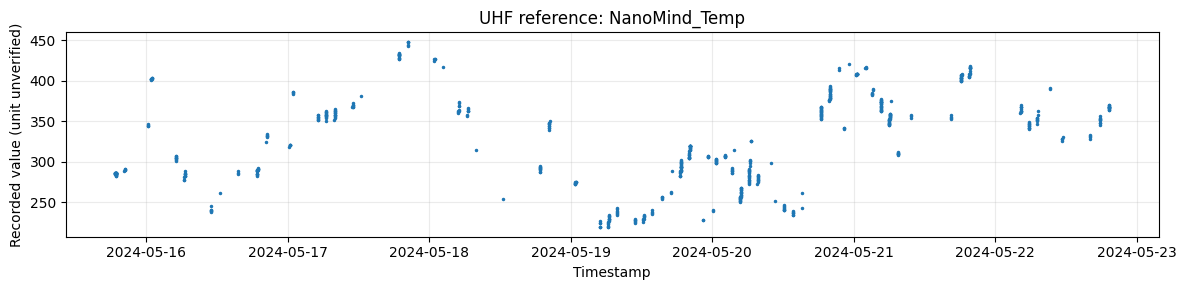

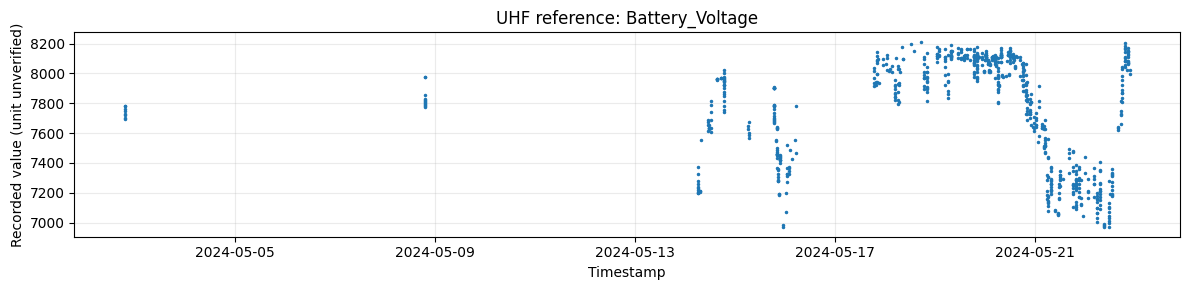

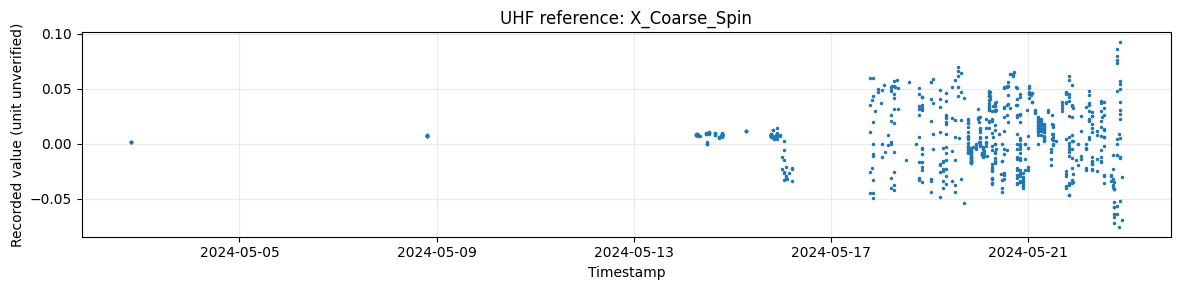

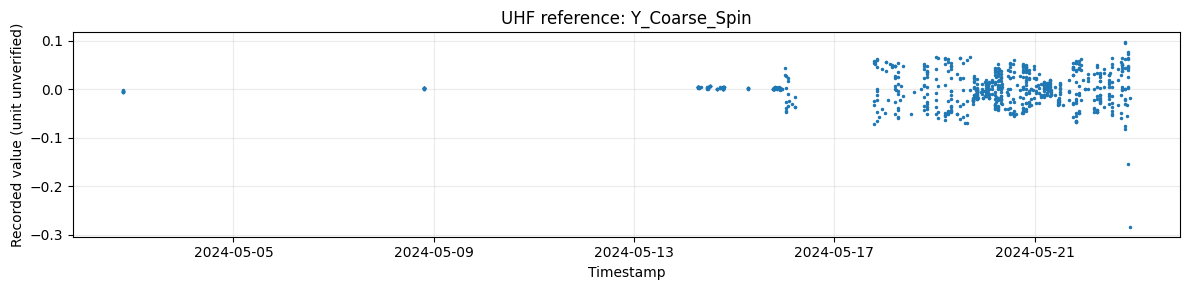

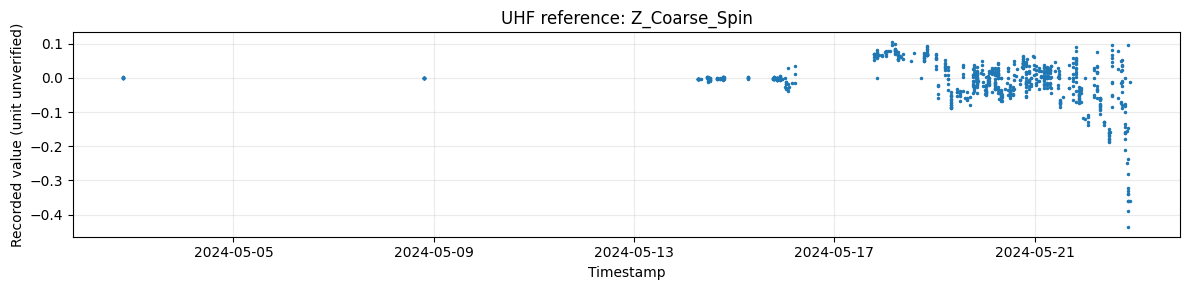

In [5]:
for col in REFERENCE_COLUMNS:
    d = uhf[[TIMESTAMP_COLUMN, col]].dropna().sort_values(TIMESTAMP_COLUMN)
    if d.empty:
        print(f'No numeric samples for {col}'); continue
    plt.figure(figsize=(12, 3))
    plt.plot(d[TIMESTAMP_COLUMN], d[col], '.', markersize=3)
    plt.title(f'UHF reference: {col}')
    plt.ylabel('Recorded value (unit unverified)'); plt.xlabel('Timestamp')
    plt.grid(alpha=.25); plt.tight_layout(); plt.show()

### A3. Reference interpretation to verify

The plots confirm the sparsity: each reference channel is populated for only a fraction of the timeline, with irregular spacing and multi-day outages. Enough for a *naming/reference* role; nowhere near enough to represent a dense multi-year sensor stream.

- `NanoMind_Temp` is the chosen temperature-like reference, but may not match the BME280's location or ambient response. Check other named temperature channels only if this one has poor coverage.
- `Battery_Voltage` is a voltage proxy, not current/power, and may not be the Pi's rail. Values may be scaled; do not convert without a channel dictionary.
- `X/Y/Z_Coarse_Spin` is a spin/motion proxy. Confirm whether it is a measured gyro signal or an ADCS estimate, its units, and coordinate frame.
- `ADCS_mode` may describe different nominal regimes. `PD1_CSS_theta`–`PD6_CSS_theta` are sun-sensor angle-like fields, not linear acceleration.

**Outcome for Part A:** UHF is retained as a *named semantic reference for streaming/mock-sensor work*. It is excluded from dense model training. There is no pressure, humidity, current, power, or linear-acceleration channel in this export.


## Part B — ESA Anomaly Dataset (anonymized telemetry)

### B1. Zenodo record metadata (no file download)

Three mission archives, ~3.5–3.9 GiB each (~10.8 GiB total). Listing sizes and checksums first avoids downloading everything before we know what is needed.

| Archive | Size |
| --- | --- |
| `ESA-Mission1.zip` | ~3.52 GiB |
| `ESA-Mission2.zip` | ~3.82 GiB |
| `ESA-Mission3.zip` | ~3.48 GiB |

Archive entries use **Deflate64** (ZIP compression method `9`), which Python's built-in `zipfile` cannot decode. That is why a decoder package is installed in B2.


In [7]:
import requests
import pandas as pd

record_id = "15237121"
url = f"https://zenodo.org/api/records/{record_id}"

response = requests.get(url, timeout=30)
response.raise_for_status()
record = response.json()

metadata = record.get("metadata") or {}
links = record.get("links") or {}

print("Title:", metadata.get("title"))
print("Version:", metadata.get("version") or "not supplied")
print("Record:", links.get("html") or f"https://zenodo.org/records/{record_id}")

files = record.get("files") or []
if isinstance(files, dict):
    files = files.get("entries") or []
if not isinstance(files, list):
    files = []

rows = []
for item in files:
    item_links = item.get("links") or {}
    size = item.get("size")
    rows.append({
        "name": item.get("key"),
        "size_bytes": size,
        "size_MiB": round(size / (1024 ** 2), 2) if size is not None else None,
        "checksum": item.get("checksum"),
        "url": item_links.get("self"),
    })

display(pd.DataFrame(rows))

Title: ESA Anomaly Dataset
Version: not supplied
Record: https://zenodo.org/records/15237121


,name,size_bytes,size_MiB,checksum,url
0,ESA-Mission1.zip,3776246073,3601.31,md5:9770ad12ed730238f37c42d5c27ab436,https://zenodo.org/api/records/15237121/files/...
1,ESA-Mission2.zip,4098539932,3908.67,md5:bfc72012691427d9327eb41f726ce45e,https://zenodo.org/api/records/15237121/files/...
2,ESA-Mission3.zip,3734403444,3561.40,md5:d63943f09c81378acd9fc5e565ecc66e,https://zenodo.org/api/records/15237121/files/...


### B1.1 Optional: download one archive locally (faster iteration)

Only needed if you plan to re-read many channels repeatedly. The cell verifies free disk space, downloads the archive, and checks the MD5 against the published value.

**The screening below was completed using remote range reads instead**, so this step is optional and can be skipped. The rest of the notebook works with or without a local copy:

- cells that read `OUTER_ZIP_PATH` need the **local** Mission 1 archive,
- cells using `RemoteZip` need only network access to Zenodo.


In [9]:
import hashlib
import shutil
from pathlib import Path
from urllib.parse import quote

import requests

missions = {
    "Mission1": {
        "filename": "ESA-Mission1.zip",
        "size_bytes": 3776246073,
        "md5": "9770ad12ed730238f37c42d5c27ab436",
    },
    "Mission2": {
        "filename": "ESA-Mission2.zip",
        "size_bytes": 4098539932,
        "md5": "bfc72012691427d9327eb41f726ce45e",
    },
    "Mission3": {
        "filename": "ESA-Mission3.zip",
        "size_bytes": 3734403444,
        "md5": "d63943f09c81378acd9fc5e565ecc66e",
    },
}

# Start with one mission. Change this to "Mission2" or "Mission3" to inspect another.
SELECTED_MISSION = "Mission1"

item = missions[SELECTED_MISSION]
filename = item["filename"]
expected_bytes = item["size_bytes"]
expected_md5 = item["md5"]

# Check that Colab has enough free space for the ZIP plus a small buffer.
free_bytes = shutil.disk_usage("/content").free
if free_bytes < expected_bytes + 256 * 1024**2:
    raise OSError(
        f"Not enough free space in /content. "
        f"ZIP needs about {expected_bytes / 1024**3:.2f} GiB; "
        f"available: {free_bytes / 1024**3:.2f} GiB."
    )

download_url = (
    "https://zenodo.org/api/records/15237121/files/"
    f"{quote(filename, safe='')}/content"
)
target = Path("/content") / filename

if target.exists() and target.stat().st_size == expected_bytes:
    print(f"Already downloaded: {target}")
else:
    print(f"Downloading {filename} ({expected_bytes / 1024**3:.2f} GiB)...")
    digest = hashlib.md5()

    with requests.get(download_url, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with target.open("wb") as output:
            for chunk in response.iter_content(chunk_size=8 * 1024**2):
                if chunk:
                    output.write(chunk)
                    digest.update(chunk)

    actual_bytes = target.stat().st_size
    if actual_bytes != expected_bytes:
        raise ValueError(
            f"Downloaded size mismatch: expected {expected_bytes}, got {actual_bytes}"
        )

    actual_md5 = digest.hexdigest()
    if actual_md5 != expected_md5:
        raise ValueError(
            f"MD5 mismatch: expected {expected_md5}, got {actual_md5}"
        )

    print("Download and MD5 check succeeded.")

OUTER_ZIP_PATH = str(target)
print("Use this path in the ZIP inventory cell:", OUTER_ZIP_PATH)

Download and MD5 check succeeded.
Use this path in the ZIP inventory cell: /content/ESA-Mission1.zip


### B2. Read the channel catalogs

`channels.csv` is small, so the catalog can be read directly — from a downloaded archive in the next cell, or over HTTP range requests in the cell after it.

The catalog is the only place that describes what exists, and it uses anonymized codes:

| Column | Meaning |
| --- | --- |
| `Channel` | channel id (`channel_41`, …) |
| `Subsystem` | anonymized structural group (`subsystem_5`) |
| `Physical Unit` | anonymized unit code (`physical_unit_4`), sometimes missing |
| `Group` | numeric group within that subsystem/unit pair |
| `Target` | `YES` when the channel is an anomaly-benchmark target |
| `Categorical` | `YES` when the channel is state-like rather than continuous |

**Archive compression note.** `compression_method: 9` is Deflate64. The next cells install `zipfile-deflate64` (which patches `zipfile`) and `remotezip` (HTTP range reads), then read the catalog. Both must be imported before any entry is opened.


In [18]:
%pip -q install zipfile-deflate64 remotezip

import zipfile_deflate64  # Adds Deflate64 support to Python's zipfile reader.

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [19]:
import zipfile
import pandas as pd

OUTER_ZIP_PATH = "/content/ESA-Mission1.zip"

with zipfile.ZipFile(OUTER_ZIP_PATH) as archive:
    matches = [
        name for name in archive.namelist()
        if name.lower().endswith("/channels.csv")
    ]
    if not matches:
        raise FileNotFoundError("Could not find channels.csv in the ZIP")

    member = matches[0]
    info = archive.getinfo(member)
    print("Catalog member:", member)
    print("ZIP compression method:", info.compress_type)

    with archive.open(member) as csv_file:
        mission1_channels = pd.read_csv(csv_file)

columns_to_show = [
    c for c in [
        "Channel", "Subsystem", "Physical Unit",
        "Group", "Target", "Categorical"
    ]
    if c in mission1_channels.columns
]
display(mission1_channels[columns_to_show])

Catalog member: ESA-Mission1/channels.csv
ZIP compression method: 9


,Channel,Subsystem,Physical Unit,Group,Target,Categorical
0,channel_1,subsystem_1,physical_unit_1,1,NO,NO
1,channel_2,subsystem_1,physical_unit_1,1,NO,NO
2,channel_3,subsystem_1,physical_unit_1,1,NO,NO
3,channel_4,subsystem_1,physical_unit_2,2,NO,NO
4,channel_5,subsystem_1,physical_unit_2,2,NO,NO
...,...,...,...,...,...,...
71,channel_72,subsystem_3,physical_unit_4,18,YES,NO
72,channel_73,subsystem_3,physical_unit_4,18,YES,NO
73,channel_74,subsystem_3,physical_unit_4,18,YES,NO
74,channel_75,subsystem_3,physical_unit_4,18,YES,NO


### B2.1 Read all three mission catalogs without downloading the archives

`RemoteZip` fetches only the ZIP central directory and the small `channels.csv` entries. With `zipfile_deflate64` imported first, this works despite the Deflate64 compression — so the full ~10.8 GiB is never transferred.

**Result: 224 mission-channel entries.**

| Mission | Channels |
| --- | --- |
| Mission 1 | 76 |
| Mission 2 | 100 |
| Mission 3 | 48 |

`all_channels` is the working catalog for every later cell.


In [20]:
import zipfile_deflate64  # Must be imported before opening entries.
from remotezip import RemoteZip
import pandas as pd

mission_urls = {
    "Mission1": "https://zenodo.org/records/15237121/files/ESA-Mission1.zip",
    "Mission2": "https://zenodo.org/records/15237121/files/ESA-Mission2.zip",
    "Mission3": "https://zenodo.org/records/15237121/files/ESA-Mission3.zip",
}

catalogs = []

for mission, url in mission_urls.items():
    print(f"Reading {mission} catalog...")
    with RemoteZip(url, timeout=60) as archive:
        matches = [
            name for name in archive.namelist()
            if name.lower().endswith("/channels.csv")
        ]
        if not matches:
            raise FileNotFoundError(f"Could not find channels.csv in {mission}")

        info = archive.getinfo(matches[0])
        print(f"  member={matches[0]}, compression_method={info.compress_type}")

        with archive.open(matches[0]) as csv_file:
            catalog = pd.read_csv(csv_file)

    catalog.insert(0, "Mission", mission)
    catalogs.append(catalog)

all_channels = pd.concat(catalogs, ignore_index=True)

print("Catalog rows per mission:")
display(all_channels.groupby("Mission").size().rename("channel_count").to_frame())

columns_to_show = [
    c for c in [
        "Mission", "Channel", "Subsystem", "Physical Unit",
        "Group", "Target", "Categorical"
    ]
    if c in all_channels.columns
]
display(all_channels[columns_to_show])

Reading Mission1 catalog...
  member=ESA-Mission1/channels.csv, compression_method=9
Reading Mission2 catalog...
  member=ESA-Mission2/channels.csv, compression_method=9
Reading Mission3 catalog...
  member=ESA-Mission3/channels.csv, compression_method=9
Catalog rows per mission:


,channel_count
Mission,
Mission1,76
Mission2,100
Mission3,48


,Mission,Channel,Subsystem,Physical Unit,Group,Target,Categorical
0,Mission1,channel_1,subsystem_1,physical_unit_1,1,NO,NO
1,Mission1,channel_2,subsystem_1,physical_unit_1,1,NO,NO
2,Mission1,channel_3,subsystem_1,physical_unit_1,1,NO,NO
3,Mission1,channel_4,subsystem_1,physical_unit_2,2,NO,NO
4,Mission1,channel_5,subsystem_1,physical_unit_2,2,NO,NO
...,...,...,...,...,...,...,...
219,Mission3,channel_44,subsystem_5,NaN,8,YES,YES
220,Mission3,channel_45,subsystem_1,NaN,1,YES,YES
221,Mission3,channel_46,subsystem_1,NaN,10,NO,YES
222,Mission3,channel_47,subsystem_1,NaN,11,NO,YES


### B2.2 What the `Target` flag actually means

`Target=YES` marks channels used as **anomaly benchmark targets**. It is *not* a sensor-type label: it says "this channel carries annotations worth evaluating against", not "this is temperature".

Because a channel can be a perfectly good signal without being an anomaly target, this screening keeps `Target=NO` continuous channels in the pool and uses `Target` only as annotation metadata. Treating it as a sensor hint would be a misreading of the dataset.

Counts: **129 of 224** entries are `Target=YES` — Mission 1: 58, Mission 2: 47, Mission 3: 24.


In [21]:
channel_columns = [
    c for c in [
        "Mission", "Channel", "Subsystem", "Physical Unit",
        "Group", "Target", "Categorical"
    ]
    if c in all_channels.columns
]

target_channels = all_channels[
    all_channels["Target"].astype(str).str.upper().eq("YES")
][channel_columns].sort_values(["Mission", "Channel"])

print("Target-flagged channels per mission:")
display(target_channels.groupby("Mission").size().rename("count").to_frame())

display(target_channels)

Target-flagged channels per mission:


,count
Mission,
Mission1,58
Mission2,47
Mission3,24


,Mission,Channel,Subsystem,Physical Unit,Group,Target,Categorical
11,Mission1,channel_12,subsystem_6,physical_unit_3,3,YES,NO
12,Mission1,channel_13,subsystem_6,physical_unit_3,3,YES,NO
13,Mission1,channel_14,subsystem_6,physical_unit_3,4,YES,NO
14,Mission1,channel_15,subsystem_6,physical_unit_3,7,YES,NO
15,Mission1,channel_16,subsystem_6,physical_unit_3,6,YES,NO
...,...,...,...,...,...,...,...
219,Mission3,channel_44,subsystem_5,NaN,8,YES,YES
220,Mission3,channel_45,subsystem_1,NaN,1,YES,YES
182,Mission3,channel_7,subsystem_5,NaN,7,YES,YES
183,Mission3,channel_8,subsystem_5,NaN,8,YES,YES


### B2.3 Continuous vs categorical channels

Model input must be continuous. `Categorical=YES` channels are state-like and belong in model *context* (e.g. operating mode) rather than as numeric series.

Cross-tab of mission × target × categorical:

| Mission | Target | Categorical | Channels |
| --- | --- | --- | --- |
| Mission 1 | NO | NO | 18 |
| Mission 1 | YES | NO | 58 |
| Mission 2 | NO | NO | 43 |
| Mission 2 | NO | YES | 10 |
| Mission 2 | YES | NO | 47 |
| Mission 3 | NO | NO | 4 |
| Mission 3 | NO | YES | 20 |
| Mission 3 | YES | YES | 24 |

So there are **170 non-categorical channels** overall (76 / 90 / 4), of which **105 are `Target=YES`** (58 Mission 1, 47 Mission 2). Mission 3's 24 target channels are all categorical, so Mission 3 contributes **no continuous target benchmark**.


In [22]:
catalog = all_channels.copy()

for column in ["Target", "Categorical"]:
    catalog[column] = catalog[column].astype("string").str.strip().str.upper()

print("Counts by mission, target flag, and categorical flag:")
display(
    catalog.groupby(
        ["Mission", "Target", "Categorical"],
        dropna=False
    ).size().rename("channels").reset_index()
)

Counts by mission, target flag, and categorical flag:


,Mission,Target,Categorical,channels
0,Mission1,NO,NO,18
1,Mission1,YES,NO,58
2,Mission2,NO,NO,43
3,Mission2,NO,YES,10
4,Mission2,YES,NO,47
5,Mission3,NO,NO,4
6,Mission3,NO,YES,20
7,Mission3,YES,YES,24


### B2.4 Continuous target candidates

Filtering to `Target=YES` and `Categorical=NO` gives the first real candidate pool: **105 channels**.

Grouping them by `Subsystem` / `Physical Unit` shows a very uneven distribution — Mission 1 `subsystem_6 / physical_unit_3` alone holds 42 channels, while several groups hold only two or three. That structure matters for the rest of the notebook:

- a **group** of channels sharing structural codes is plausibly one multi-signal unit,
- a **size-1 group** is a scalar candidate with no cross-channel assumptions.


In [23]:
# Best initial pool for continuous sensor-like signals:
# target channels that are not marked categorical.
numeric_targets = catalog[
    catalog["Target"].eq("YES") & catalog["Categorical"].eq("NO")
].copy()

print("Continuous target-channel candidates:")
display(
    numeric_targets[
        ["Mission", "Channel", "Subsystem", "Physical Unit", "Group"]
    ].sort_values(["Mission", "Subsystem", "Physical Unit", "Group", "Channel"])
)

print("Counts by mission / subsystem / unit code:")
display(
    numeric_targets.groupby(
        ["Mission", "Subsystem", "Physical Unit"],
        dropna=False
    ).size().rename("channels").reset_index()
)

Continuous target-channel candidates:


,Mission,Channel,Subsystem,Physical Unit,Group
60,Mission1,channel_61,subsystem_1,physical_unit_6,14
61,Mission1,channel_62,subsystem_1,physical_unit_6,14
62,Mission1,channel_63,subsystem_1,physical_unit_6,14
69,Mission1,channel_70,subsystem_3,physical_unit_4,18
70,Mission1,channel_71,subsystem_3,physical_unit_4,18
...,...,...,...,...,...
164,Mission2,channel_89,subsystem_6,physical_unit_3,13
165,Mission2,channel_90,subsystem_6,physical_unit_3,13
166,Mission2,channel_91,subsystem_6,physical_unit_3,13
133,Mission2,channel_58,subsystem_6,physical_unit_3,18


Counts by mission / subsystem / unit code:


,Mission,Subsystem,Physical Unit,channels
0,Mission1,subsystem_1,physical_unit_6,3
1,Mission1,subsystem_3,physical_unit_4,7
2,Mission1,subsystem_5,physical_unit_4,6
3,Mission1,subsystem_6,physical_unit_3,42
4,Mission2,subsystem_1,physical_unit_9,4
5,Mission2,subsystem_1,NaN,16
6,Mission2,subsystem_2,NaN,3
7,Mission2,subsystem_5,physical_unit_4,14
8,Mission2,subsystem_5,physical_unit_5,2
9,Mission2,subsystem_6,physical_unit_3,8


### B2.5 Group summary across all continuous channels

The same view, but across **every** continuous channel (target and non-target). This is deliberate: a sensor-like signal does not need to be an anomaly target to be a useful proxy, and restricting to targets here would bias the screening.

Read `channel_count` as "how many channels share this structural group". The largest groups are the Mission 1 `subsystem_6 / physical_unit_3` clusters (up to 8 channels) and the Mission 2 `subsystem_1 / physical_unit_2` cluster (18 channels). Those large groups are the ones worth checking for synchronized behaviour later in B4.


In [24]:
continuous = all_channels[
    all_channels["Categorical"].astype(str).str.strip().str.upper().eq("NO")
].copy()

group_summary = (
    continuous
    .groupby(
        ["Mission", "Subsystem", "Physical Unit", "Group", "Target"],
        dropna=False
    )
    .agg(
        channel_count=("Channel", "size"),
        channels=("Channel", lambda s: ", ".join(s.astype(str)))
    )
    .reset_index()
    .sort_values(
        ["Mission", "channel_count", "Subsystem", "Group"],
        ascending=[True, False, True, True]
    )
)

display(group_summary[group_summary["channel_count"] >= 2])

,Mission,Subsystem,Physical Unit,Group,Target,channel_count,channels
1,Mission1,subsystem_1,physical_unit_2,2,NO,8,"channel_4, channel_5, channel_6, channel_7, ch..."
8,Mission1,subsystem_6,physical_unit_3,3,YES,8,"channel_12, channel_13, channel_19, channel_20..."
4,Mission1,subsystem_3,physical_unit_4,18,YES,7,"channel_70, channel_71, channel_72, channel_73..."
7,Mission1,subsystem_5,physical_unit_4,8,YES,6,"channel_41, channel_42, channel_43, channel_44..."
10,Mission1,subsystem_6,physical_unit_3,5,YES,6,"channel_17, channel_18, channel_25, channel_26..."
9,Mission1,subsystem_6,physical_unit_3,4,YES,5,"channel_14, channel_21, channel_29, channel_30..."
11,Mission1,subsystem_6,physical_unit_3,6,YES,5,"channel_16, channel_24, channel_32, channel_33..."
12,Mission1,subsystem_6,physical_unit_3,7,YES,5,"channel_15, channel_22, channel_23, channel_31..."
15,Mission1,subsystem_6,physical_unit_3,13,YES,4,"channel_57, channel_58, channel_59, channel_60"
0,Mission1,subsystem_1,physical_unit_1,1,NO,3,"channel_1, channel_2, channel_3"


## Part B3 — Channel-level profiling

Profiling answers four practical questions per candidate:

1. **Volume** — how many numeric samples exist?
2. **Cadence and gaps** — is it a regular stream, and how long are the outages?
3. **Range and shape** — bounded, saturated, near-constant, or genuinely varying?
4. **Annotation coverage** — how many labelled windows does it have?


### B3.1 First structural candidate: Mission 1 `channel_61–63`

Chosen because all three share subsystem, physical-unit, and group codes — the strongest structural hint of a multi-axis signal in the catalog.

**Result:** 487,448 samples each, **identical timestamps**, 15-minute median cadence, values bounded in `[0, 1]`, maximum gap ~23 days.

**Interpretation:** a genuinely synchronized three-channel group, worth keeping — but a 15-minute cadence with 0–1 values does not match raw gyro or accelerometer output. Treated as a generic *vector-like* stream, not an IMU.


In [25]:
import io
import zipfile
import zipfile_deflate64  # Enables method 9 (Deflate64).
import numpy as np
import pandas as pd

OUTER_ZIP_PATH = "/content/ESA-Mission1.zip"
CHANNELS_TO_TEST = ["channel_61", "channel_62", "channel_63"]

def read_channel_frame(outer, channel):
    suffix = f"/channels/{channel}.zip"
    matches = [name for name in outer.namelist() if name.endswith(suffix)]
    if not matches:
        raise FileNotFoundError(f"Could not find {channel}.zip in the outer archive")

    # Read only this channel's nested ZIP into memory.
    nested_bytes = outer.read(matches[0])

    with zipfile.ZipFile(io.BytesIO(nested_bytes)) as nested:
        data_files = [name for name in nested.namelist() if not name.endswith("/")]
        if len(data_files) != 1:
            raise ValueError(f"Expected one data file in {channel}.zip; found {data_files}")
        with nested.open(data_files[0]) as data_file:
            return pd.read_pickle(data_file)

def profile_channel(channel, frame):
    value_columns = [c for c in frame.columns if c != "label"]
    if channel in value_columns:
        value_column = channel
    elif len(value_columns) == 1:
        value_column = value_columns[0]
    else:
        raise ValueError(f"Couldn't identify the value column in {channel}: {value_columns}")

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce"),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time")

    gaps = data["time"].diff().dt.total_seconds().dropna()
    values = data["value"]

    return {
        "channel": channel,
        "rows_in_file": len(frame),
        "numeric_rows": len(data),
        "start": data["time"].min(),
        "end": data["time"].max(),
        "median_gap_seconds": gaps.median() if len(gaps) else np.nan,
        "max_gap_hours": gaps.max() / 3600 if len(gaps) else np.nan,
        "min": values.min(),
        "p01": values.quantile(0.01),
        "median": values.median(),
        "p99": values.quantile(0.99),
        "max": values.max(),
    }

frames = {}

with zipfile.ZipFile(OUTER_ZIP_PATH) as outer:
    profiles = []
    for channel in CHANNELS_TO_TEST:
        frame = read_channel_frame(outer, channel)
        frames[channel] = frame
        profiles.append(profile_channel(channel, frame))

display(pd.DataFrame(profiles))

,channel,rows_in_file,numeric_rows,start,end,median_gap_seconds,max_gap_hours,min,p01,median,p99,max
0,channel_61,487448,487448,2000-01-01 00:06:45.177,2013-12-31 23:57:38.481,900.0,549.893884,0.000511,0.001545,0.560166,0.999239,1.000000
1,channel_62,487448,487448,2000-01-01 00:06:45.177,2013-12-31 23:57:38.481,900.0,549.893884,0.045605,0.046091,0.469978,0.967593,0.968291
2,channel_63,487448,487448,2000-01-01 00:06:45.177,2013-12-31 23:57:38.481,900.0,549.893884,0.307905,0.308190,0.491681,0.707628,0.707881


### B3.2 Annotation check for `channel_61–63`

Joins `labels.csv` (channel, start, end, anomaly id) with `anomaly_types.csv` (category, class, subclass).

**Result:** all three channels carry the **same five annotation intervals** — 3 `Anomaly` and 2 `Rare Event`. These are five *shared* events, not 15 independent ones. The 671-hour `Anomaly` interval also overlaps one of the `Rare Event` intervals.

This is why later sections count **windows** and **group-level unions** instead of adding up per-channel counts.


In [26]:
import zipfile_deflate64  # Deflate64 support; keep before opening the ZIP.
import zipfile
import pandas as pd

OUTER_ZIP_PATH = "/content/ESA-Mission1.zip"
CHANNELS_TO_CHECK = ["channel_61", "channel_62", "channel_63"]

with zipfile.ZipFile(OUTER_ZIP_PATH) as archive:
    labels_file = next(
        name for name in archive.namelist()
        if name.lower().endswith("/labels.csv")
    )
    types_file = next(
        name for name in archive.namelist()
        if name.lower().endswith("/anomaly_types.csv")
    )

    with archive.open(labels_file) as f:
        labels = pd.read_csv(f)

    with archive.open(types_file) as f:
        anomaly_types = pd.read_csv(f)

channel_labels = labels[labels["Channel"].isin(CHANNELS_TO_CHECK)].merge(
    anomaly_types[["ID", "Class", "Subclass", "Category"]],
    on="ID",
    how="left",
)

if channel_labels.empty:
    print("No label intervals found for these channels.")
else:
    channel_labels["StartTime"] = pd.to_datetime(
        channel_labels["StartTime"], errors="coerce"
    )
    channel_labels["EndTime"] = pd.to_datetime(
        channel_labels["EndTime"], errors="coerce"
    )
    channel_labels["duration_hours"] = (
        channel_labels["EndTime"] - channel_labels["StartTime"]
    ).dt.total_seconds() / 3600

    display(channel_labels.sort_values(["Channel", "StartTime"]))
    display(
        channel_labels.groupby(["Channel", "Category"], dropna=False)
        .size()
        .rename("label_intervals")
        .to_frame()
    )

,ID,Channel,StartTime,EndTime,Class,Subclass,Category,duration_hours
6,id_116,channel_61,2007-04-15 00:41:23.373000+00:00,2007-04-15 00:41:23.373000+00:00,class_14,subclass_3,Anomaly,0.000000
3,id_43,channel_61,2008-11-27 15:12:23.775000+00:00,2008-11-30 15:12:23.775000+00:00,class_13,subclass_1,Anomaly,72.000000
9,id_134,channel_61,2009-05-25 13:12:23.748000+00:00,2009-06-22 12:42:38.745000+00:00,class_14,subclass_4,Anomaly,671.504166
0,id_34,channel_61,2009-06-10 20:07:29.031000+00:00,2009-06-10 23:35:59.031000+00:00,class_8,subclass_1,Rare Event,3.475000
12,id_180,channel_61,2013-08-12 15:12:38.505000+00:00,2013-08-15 15:12:38.505000+00:00,class_2,subclass_4,Rare Event,72.000000
7,id_116,channel_62,2007-04-15 00:41:23.373000+00:00,2007-04-15 00:41:23.373000+00:00,class_14,subclass_3,Anomaly,0.000000
4,id_43,channel_62,2008-11-27 15:12:23.775000+00:00,2008-11-30 15:12:23.775000+00:00,class_13,subclass_1,Anomaly,72.000000
10,id_134,channel_62,2009-05-25 13:12:23.748000+00:00,2009-06-22 12:42:38.745000+00:00,class_14,subclass_4,Anomaly,671.504166
1,id_34,channel_62,2009-06-10 20:07:29.031000+00:00,2009-06-10 23:35:59.031000+00:00,class_8,subclass_1,Rare Event,3.475000
13,id_180,channel_62,2013-08-12 15:12:38.505000+00:00,2013-08-15 15:12:38.505000+00:00,class_2,subclass_4,Rare Event,72.000000


label_intervals
Channel    Category                   
channel_61 Anomaly                   3
           Rare Event                2
channel_62 Anomaly                   3
           Rare Event                2
channel_63 Anomaly                   3
           Rare Event                2

### B3.3 Scalar candidates (groups of size 1)

Continuous channels that are alone in their mission / subsystem / unit / group. These are the simplest possible model inputs: one signal, no cross-channel assumptions.

**Result:** only three — Mission 1 `channel_66`, Mission 2 `channel_99` and `channel_100`.

Restricting to size-1 groups is a screening device, not a claim that scalar signals only exist there — several multi-channel groups also contain independently useful channels.


In [27]:
numeric = all_channels[
    all_channels["Categorical"].astype(str).str.strip().str.upper().eq("NO")
].copy()

group_keys = ["Mission", "Subsystem", "Physical Unit", "Group"]
numeric["group_size"] = numeric.groupby(
    group_keys, dropna=False
)["Channel"].transform("size")

scalar_candidates = numeric[numeric["group_size"].eq(1)]

display(
    scalar_candidates[
        [
            "Mission", "Channel", "Subsystem", "Physical Unit",
            "Group", "Target"
        ]
    ].sort_values(["Mission", "Subsystem", "Physical Unit", "Group"])
)

,Mission,Channel,Subsystem,Physical Unit,Group,Target
65,Mission1,channel_66,subsystem_6,physical_unit_3,16,YES
175,Mission2,channel_100,subsystem_1,physical_unit_10,32,NO
174,Mission2,channel_99,subsystem_1,NaN,24,NO


### B3.4 Profile the three scalar candidates (remote, size-limited)

Reads only the three nested channel ZIPs via range requests, with a 128 MiB per-file safety limit.

| Channel | Samples | Cadence | Range | Assessment |
| --- | --- | --- | --- | --- |
| Mission 1 `channel_66` | 4,810,995 | 2.6 min | 0–1; p01–p99 ≈ 0.9917–0.9938 | near-constant nominal band, occasional zeros — promising |
| Mission 2 `channel_99` | 7,387,295 | 18 s | 0–1; median 1.0, ~10% zeros | heavily clipped / state-like — fallback only |
| Mission 2 `channel_100` | 1,703 | ~18 h | 0.25–1.0 | far too sparse for a stream — **dropped** |

`channel_66` becomes the first serious candidate: it is the only scalar channel with both useful density and annotations.


In [28]:
import io
import zipfile
import zipfile_deflate64  # Support ZIP method 9 (Deflate64).
from remotezip import RemoteZip
import numpy as np
import pandas as pd

mission_urls = {
    "Mission1": "https://zenodo.org/records/15237121/files/ESA-Mission1.zip",
    "Mission2": "https://zenodo.org/records/15237121/files/ESA-Mission2.zip",
    "Mission3": "https://zenodo.org/records/15237121/files/ESA-Mission3.zip",
}

candidates = [
    ("Mission1", "channel_66"),
    ("Mission2", "channel_99"),
    ("Mission2", "channel_100"),
]
MAX_CHANNEL_ZIP_MIB = 128

def read_remote_channel(mission, channel):
    url = mission_urls[mission]
    suffix = f"/channels/{channel}.zip"

    with RemoteZip(url, timeout=60) as outer:
        matches = [name for name in outer.namelist() if name.endswith(suffix)]
        if not matches:
            raise FileNotFoundError(f"{channel}.zip not found in {mission}")

        info = outer.getinfo(matches[0])
        size_mib = info.file_size / (1024 ** 2)
        print(f"{mission}/{channel}: nested ZIP is {size_mib:.1f} MiB")

        if size_mib > MAX_CHANNEL_ZIP_MIB:
            raise ValueError(
                f"{channel}.zip exceeds the {MAX_CHANNEL_ZIP_MIB} MiB safety limit"
            )

        nested_bytes = outer.read(matches[0])

    with zipfile.ZipFile(io.BytesIO(nested_bytes)) as nested:
        data_files = [name for name in nested.namelist() if not name.endswith("/")]
        if len(data_files) != 1:
            raise ValueError(f"Expected one data file in {channel}.zip; found {data_files}")
        with nested.open(data_files[0]) as data_file:
            return pd.read_pickle(data_file)

def profile_channel(mission, channel, frame):
    value_columns = [c for c in frame.columns if c != "label"]
    value_column = channel if channel in value_columns else value_columns[0]

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce", utc=True),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time")

    gaps = data["time"].diff().dt.total_seconds().dropna()
    values = data["value"]

    return {
        "Mission": mission,
        "Channel": channel,
        "rows": len(frame),
        "numeric_rows": len(data),
        "start": data["time"].min(),
        "end": data["time"].max(),
        "median_gap_min": gaps.median() / 60 if len(gaps) else np.nan,
        "max_gap_days": gaps.max() / 86400 if len(gaps) else np.nan,
        "min": values.min(),
        "p01": values.quantile(0.01),
        "median": values.median(),
        "p99": values.quantile(0.99),
        "max": values.max(),
        "zero_pct": 100 * values.eq(0).mean() if len(values) else np.nan,
    }

profiles = []
for mission, channel in candidates:
    frame = read_remote_channel(mission, channel)
    profiles.append(profile_channel(mission, channel, frame))

display(pd.DataFrame(profiles))

Mission1/channel_66: nested ZIP is 22.1 MiB
Mission2/channel_99: nested ZIP is 34.6 MiB
Mission2/channel_100: nested ZIP is 0.0 MiB


,Mission,Channel,rows,numeric_rows,start,end,median_gap_min,max_gap_days,min,p01,median,p99,max,zero_pct
0,Mission1,channel_66,4810995,4810995,2000-01-01 00:02:24.552000+00:00,2013-12-31 23:59:17.856000+00:00,2.625,1.176771,0.000000,0.991651,0.992579,0.993816,1.0,0.035357
1,Mission2,channel_99,7387295,7387295,2000-01-01 00:00:16.285000+00:00,2003-06-30 23:59:52.419000+00:00,0.300,0.026250,0.000000,0.466667,1.000000,1.000000,1.0,0.104504
2,Mission2,channel_100,1703,1703,2000-01-01 00:00:00+00:00,2003-06-30 12:00:00+00:00,1080.000,0.750000,0.248263,0.249553,0.700108,0.999507,1.0,0.000000


### B3.5 Does `channel_66` actually change during its labelled windows?

For each of its 16 annotations, compare values inside the window against the medians two days before and after.

**Result:** a mix. Some windows show clear excursions — `id_84`, `id_112`, `id_116`, `id_134` contain zeros or out-of-band values — while many others stay inside the normal ~0.993 band.

**Interpretation:** useful as a *generic* anomaly stream covering both easy and subtle events, which is what a benchmark should contain. Its physical meaning remains unknown.


In [29]:
import io
import zipfile
import zipfile_deflate64
import numpy as np
import pandas as pd

OUTER_ZIP_PATH = "/content/ESA-Mission1.zip"
CHANNEL = "channel_66"

with zipfile.ZipFile(OUTER_ZIP_PATH) as archive:
    channel_member = next(
        name for name in archive.namelist()
        if name.endswith(f"/channels/{CHANNEL}.zip")
    )
    with archive.open(channel_member) as raw:
        channel_zip_bytes = raw.read()

    with zipfile.ZipFile(io.BytesIO(channel_zip_bytes)) as channel_zip:
        data_files = [name for name in channel_zip.namelist() if not name.endswith("/")]
        with channel_zip.open(data_files[0]) as data_file:
            frame = pd.read_pickle(data_file)

    labels_member = next(
        name for name in archive.namelist()
        if name.endswith("/labels.csv")
    )
    types_member = next(
        name for name in archive.namelist()
        if name.endswith("/anomaly_types.csv")
    )
    with archive.open(labels_member) as f:
        labels = pd.read_csv(f)
    with archive.open(types_member) as f:
        anomaly_types = pd.read_csv(f)

value_columns = [c for c in frame.columns if c != "label"]
value_column = CHANNEL if CHANNEL in value_columns else value_columns[0]

series = pd.Series(
    pd.to_numeric(frame[value_column], errors="coerce").to_numpy(),
    index=pd.to_datetime(frame.index, errors="coerce", utc=True),
).dropna().sort_index()

events = labels[labels["Channel"].eq(CHANNEL)].merge(
    anomaly_types[["ID", "Category", "Class", "Subclass"]],
    on="ID",
    how="left",
)
events["StartTime"] = pd.to_datetime(events["StartTime"], errors="coerce", utc=True)
events["EndTime"] = pd.to_datetime(events["EndTime"], errors="coerce", utc=True)

rows = []
for _, event in events.iterrows():
    start, end = event["StartTime"], event["EndTime"]
    values = series.loc[(series.index >= start) & (series.index <= end)]

    # A zero-duration label may fall between sample timestamps; use its nearest sample.
    if values.empty:
        nearest = np.abs(series.index.asi8 - start.value).argmin()
        values = series.iloc[[nearest]]

    before = series.loc[
        (series.index >= start - pd.Timedelta(days=2)) & (series.index < start)
    ]
    after = series.loc[
        (series.index > end) & (series.index <= end + pd.Timedelta(days=2))
    ]

    rows.append({
        "ID": event["ID"],
        "Category": event["Category"],
        "StartTime": start,
        "EndTime": end,
        "samples_in_interval": len(values),
        "event_median": values.median(),
        "event_min": values.min(),
        "event_max": values.max(),
        "median_2d_before": before.median(),
        "median_2d_after": after.median(),
    })

display(pd.DataFrame(rows))

,ID,Category,StartTime,EndTime,samples_in_interval,event_median,event_min,event_max,median_2d_before,median_2d_after
0,id_25,Anomaly,2002-07-17 14:38:33.450000+00:00,2002-07-20 12:29:33.450000+00:00,1398,0.992888,0.992579,0.993197,0.993197,0.993197
1,id_33,Rare Event,2009-03-08 13:47:03.135000+00:00,2009-03-08 13:47:03.135000+00:00,1,0.993816,0.993816,0.993816,0.993816,0.993816
2,id_79,Rare Event,2001-04-23 16:32:36.501000+00:00,2001-04-25 00:38:36.498000+00:00,643,0.992888,0.991960,0.993816,0.991960,0.991960
3,id_84,Anomaly,2002-06-23 15:11:33.453000+00:00,2002-06-23 23:38:33.453000+00:00,170,0.977891,0.000000,0.986704,0.992888,0.993197
4,id_95,Rare Event,2004-09-15 23:01:48.357000+00:00,2004-09-18 17:23:55.854000+00:00,1518,0.992270,0.991960,0.992888,0.991960,0.991960
5,id_101,Anomaly,2005-09-01 19:59:00.312000+00:00,2005-09-05 09:23:00.309000+00:00,1687,0.992579,0.991651,0.993506,0.993506,0.993197
6,id_103,Anomaly,2005-10-22 13:35:00.306000+00:00,2005-10-23 01:47:00.303000+00:00,244,0.993197,0.992888,0.993506,0.993506,0.993197
7,id_112,Rare Event,2006-11-26 17:01:57.252000+00:00,2006-11-26 22:10:57.252000+00:00,104,0.000000,0.000000,0.992579,0.992579,0.993197
8,id_116,Anomaly,2007-04-14 22:53:03.234000+00:00,2007-04-20 07:02:07.410000+00:00,2563,0.996908,0.963822,1.000000,0.992270,0.991651
9,id_134,Anomaly,2009-05-26 17:28:36.120000+00:00,2009-06-27 03:20:18.117000+00:00,14584,0.990724,0.000000,0.993506,0.993506,0.992888


### B3.6 Labelled vs unlabelled distribution for `channel_66`

Aggregating all labelled windows versus all unlabelled samples:

| Set | Samples | Median | Zero % | One % | Range |
| --- | --- | --- | --- | --- | --- |
| Labelled intervals | 29,825 (≈0.62%) | 0.9920 | **5.70%** | 0.11% | 0 → 1 |
| Unlabelled | 4,781,170 | 0.9926 | **0%** | 0% | 0.9867 → 0.9947 |

This is the first strong statistical separation found in the dataset — and it also defines the honest baseline. A trivial `value == 0` rule already catches a large share of the labelled data, so any model must be compared against that rule before claiming skill.


In [31]:
import numpy as np
import pandas as pd

labelled = pd.Series(False, index=series.index)

for _, event in events.iterrows():
    start = pd.to_datetime(event["StartTime"], utc=True)
    end = pd.to_datetime(event["EndTime"], utc=True)

    if start == end:
        # Mark the nearest sample for a single-timestamp annotation.
        nearest = np.abs(series.index.asi8 - start.value).argmin()
        labelled.iloc[nearest] = True
    else:
        labelled |= (series.index >= start) & (series.index <= end)

rows = []
for name, values in [
    ("labelled intervals", series[labelled]),
    ("unlabelled", series[~labelled]),
]:
    rows.append({
        "set": name,
        "samples": len(values),
        "median": values.median(),
        "p01": values.quantile(0.01),
        "p99": values.quantile(0.99),
        "min": values.min(),
        "max": values.max(),
        "zero_pct": 100 * values.eq(0).mean(),
        "one_pct": 100 * values.eq(1).mean(),
    })

display(pd.DataFrame(rows))

,set,samples,median,p01,p99,min,max,zero_pct,one_pct
0,labelled intervals,29825,0.991960,0.000000,0.999072,0.000000,1.000000,5.703269,0.107293
1,unlabelled,4781170,0.992579,0.991651,0.993816,0.986704,0.994743,0.000000,0.000000


### B3.7 Rank all continuous channels by annotation coverage

Rather than guessing which channels to profile next, rank every continuous channel by how much annotation it carries. Only `labels.csv` and `anomaly_types.csv` are read from all three missions (small files, range requests).

Three caveats that shape how to read this table:

- `labelled_intervals` counts **unique IDs**, while `anomaly_intervals` / `rare_event_intervals` count **rows**. They are not directly comparable.
- Channels inside one group share many of the same IDs, so large counts often describe the *same* underlying events recorded against several channels.
- Mission 2's top channels are dominated by `Rare Event` labels, not `Anomaly`.

The ranking is therefore a **shortlisting device**: it shows where annotation exists, not where a model would perform well.


In [32]:
import zipfile_deflate64
from remotezip import RemoteZip
import pandas as pd

mission_urls = {
    "Mission1": "https://zenodo.org/records/15237121/files/ESA-Mission1.zip",
    "Mission2": "https://zenodo.org/records/15237121/files/ESA-Mission2.zip",
    "Mission3": "https://zenodo.org/records/15237121/files/ESA-Mission3.zip",
}

label_tables = []
type_tables = []

for mission, url in mission_urls.items():
    print(f"Reading label metadata for {mission}...")
    with RemoteZip(url, timeout=60) as archive:
        labels_name = next(
            name for name in archive.namelist()
            if name.lower().endswith("/labels.csv")
        )
        types_name = next(
            name for name in archive.namelist()
            if name.lower().endswith("/anomaly_types.csv")
        )

        with archive.open(labels_name) as f:
            labels = pd.read_csv(f)
        with archive.open(types_name) as f:
            types = pd.read_csv(f)

    labels["Mission"] = mission
    types["Mission"] = mission
    label_tables.append(labels)
    type_tables.append(types)

labels_all = pd.concat(label_tables, ignore_index=True)
types_all = pd.concat(type_tables, ignore_index=True)

label_details = labels_all.merge(
    types_all[["Mission", "ID", "Category", "Class", "Subclass"]],
    on=["Mission", "ID"],
    how="left",
)

label_summary = (
    label_details
    .groupby(["Mission", "Channel"], dropna=False)
    .agg(
        labelled_intervals=("ID", "nunique"),
        anomaly_intervals=("Category", lambda s: s.eq("Anomaly").sum()),
        rare_event_intervals=("Category", lambda s: s.eq("Rare Event").sum()),
        event_ids=("ID", lambda s: ", ".join(dict.fromkeys(s.astype(str)))),
    )
    .reset_index()
)

catalog = all_channels.copy()
for column in ["Target", "Categorical"]:
    catalog[column] = (
        catalog[column].astype("string").str.strip().str.upper()
    )

continuous = catalog[catalog["Categorical"].eq("NO")].copy()

ranked = continuous.merge(
    label_summary,
    on=["Mission", "Channel"],
    how="left",
)

for column in [
    "labelled_intervals", "anomaly_intervals", "rare_event_intervals"
]:
    ranked[column] = ranked[column].fillna(0).astype(int)

ranked["group_size"] = ranked.groupby(
    ["Mission", "Subsystem", "Physical Unit", "Group"],
    dropna=False,
)["Channel"].transform("size")

print("Continuous channels with annotations, ranked by interval count:")
display(
    ranked[ranked["labelled_intervals"] > 0]
    .sort_values(
        ["labelled_intervals", "Target"],
        ascending=[False, True],
    )
    [[
        "Mission", "Channel", "Target", "Subsystem", "Physical Unit",
        "Group", "group_size", "labelled_intervals",
        "anomaly_intervals", "rare_event_intervals", "event_ids",
    ]]
    .head(40)
)

Reading label metadata for Mission1...
Reading label metadata for Mission2...
Reading label metadata for Mission3...
Continuous channels with annotations, ranked by interval count:


,Mission,Channel,Target,Subsystem,Physical Unit,Group,group_size,labelled_intervals,anomaly_intervals,rare_event_intervals,event_ids
86,Mission2,channel_13,YES,subsystem_1,NaN,9,3,608,11,621,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
93,Mission2,channel_20,YES,subsystem_1,NaN,5,3,605,12,620,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
87,Mission2,channel_14,YES,subsystem_1,NaN,9,3,604,11,624,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
91,Mission2,channel_18,YES,subsystem_1,NaN,5,3,601,11,610,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
92,Mission2,channel_19,YES,subsystem_1,NaN,5,3,591,6,617,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
85,Mission2,channel_12,YES,subsystem_1,NaN,9,3,590,7,618,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
82,Mission2,channel_9,YES,subsystem_1,NaN,10,3,588,11,598,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
84,Mission2,channel_11,YES,subsystem_1,NaN,10,3,570,7,575,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
89,Mission2,channel_16,YES,subsystem_1,NaN,8,3,561,3,595,"id_1, id_2, id_3, id_4, id_5, id_6, id_7, id_8..."
90,Mission2,channel_17,YES,subsystem_1,NaN,8,3,554,5,580,"id_1, id_2, id_3, id_5, id_7, id_8, id_9, id_1..."


### B3.8 Profile the shortlisted candidates

Five representatives, one per distinct group or family, so the comparison is not dominated by copies of the same events:

- Mission 2 `channel_13` (group 9)
- Mission 2 `channel_20` (group 5)
- Mission 2 `channel_24` (group 2)
- Mission 1 `channel_41` (group 8)
- Mission 1 `channel_66` (scalar baseline from B3.4)

| Channel | Samples | Cadence | Anomaly windows | Rare-event windows | Shape |
| --- | --- | --- | --- | --- | --- |
| M2 `channel_13` | 7,387,262 | 18 s | 11 | 621 | extremely tight band ≈ 0.5066 |
| M2 `channel_20` | 7,387,262 | 18 s | 12 | 620 | tight band ≈ 0.4561, some outliers |
| M2 `channel_24` | 7,387,262 | 18 s | 4 | 508 | genuinely varying, 0.04–0.30 |
| M1 `channel_41` | 15,381,169 | 30 s | **53** | 154 | varying ≈ 0.81 with dips |
| M1 `channel_66` | 4,810,995 | 158 s | 10 | 6 | near-saturated ≈ 0.9926 |

`channel_41` stands out on annotation **balance**: 53 anomaly windows spread across 13 years. The Mission 2 channels carry far more labels in total, but almost all of them are `Rare Event`, which is a different phenomenon.


In [33]:
import io
import zipfile
import zipfile_deflate64
from remotezip import RemoteZip
import numpy as np
import pandas as pd

candidates = [
    ("Mission2", "channel_13"),
    ("Mission2", "channel_20"),
    ("Mission2", "channel_24"),
    ("Mission1", "channel_41"),
    ("Mission1", "channel_66"),
]
MAX_CHANNEL_ZIP_MIB = 128

def read_remote_channel(mission, channel):
    suffix = f"/channels/{channel}.zip"

    with RemoteZip(mission_urls[mission], timeout=60) as outer:
        matches = [name for name in outer.namelist() if name.endswith(suffix)]
        if not matches:
            raise FileNotFoundError(f"{mission}/{channel}.zip not found")

        member = matches[0]
        info = outer.getinfo(member)
        size_mib = info.file_size / 1024**2
        print(f"{mission}/{channel}: {size_mib:.1f} MiB")

        if size_mib > MAX_CHANNEL_ZIP_MIB:
            raise ValueError(
                f"{mission}/{channel} exceeds the {MAX_CHANNEL_ZIP_MIB} MiB limit"
            )

        nested_bytes = outer.read(member)

    with zipfile.ZipFile(io.BytesIO(nested_bytes)) as nested:
        data_files = [n for n in nested.namelist() if not n.endswith("/")]
        if len(data_files) != 1:
            raise ValueError(f"Expected one data file; found {data_files}")
        with nested.open(data_files[0]) as f:
            return pd.read_pickle(f)

def profile_candidate(mission, channel, frame):
    value_columns = [c for c in frame.columns if c != "label"]
    value_column = channel if channel in value_columns else value_columns[0]

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce", utc=True),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time")

    values = data["value"]
    gaps = data["time"].diff().dt.total_seconds().dropna()

    events = label_details[
        label_details["Mission"].eq(mission)
        & label_details["Channel"].eq(channel)
    ].copy()

    # Count unique labelled time/category windows separately from IDs and rows.
    if not events.empty:
        events["StartTime"] = pd.to_datetime(
            events["StartTime"], errors="coerce", utc=True
        )
        events["EndTime"] = pd.to_datetime(
            events["EndTime"], errors="coerce", utc=True
        )
        windows = events.drop_duplicates(
            ["StartTime", "EndTime", "Category"]
        )
        anomaly_windows = windows["Category"].eq("Anomaly").sum()
        rare_windows = windows["Category"].eq("Rare Event").sum()
    else:
        windows = events
        anomaly_windows = rare_windows = 0

    return {
        "Mission": mission,
        "Channel": channel,
        "samples": len(data),
        "start": data["time"].min(),
        "end": data["time"].max(),
        "median_gap_s": gaps.median() if len(gaps) else np.nan,
        "p95_gap_h": gaps.quantile(.95) / 3600 if len(gaps) else np.nan,
        "max_gap_days": gaps.max() / 86400 if len(gaps) else np.nan,
        "unique_values": values.nunique(),
        "p01": values.quantile(.01),
        "median": values.median(),
        "p99": values.quantile(.99),
        "std": values.std(),
        "zero_pct": 100 * values.eq(0).mean(),
        "annotation_rows": len(events),
        "unique_IDs": events["ID"].nunique() if not events.empty else 0,
        "unique_label_windows": len(windows),
        "anomaly_windows": int(anomaly_windows),
        "rare_event_windows": int(rare_windows),
    }

profiles = []
for mission, channel in candidates:
    frame = read_remote_channel(mission, channel)
    profiles.append(profile_candidate(mission, channel, frame))

display(pd.DataFrame(profiles))

Mission2/channel_13: 38.1 MiB
Mission2/channel_20: 46.6 MiB
Mission2/channel_24: 37.9 MiB
Mission1/channel_41: 79.4 MiB
Mission1/channel_66: 22.1 MiB


,Mission,Channel,samples,start,end,median_gap_s,p95_gap_h,max_gap_days,unique_values,p01,median,p99,std,zero_pct,annotation_rows,unique_IDs,unique_label_windows,anomaly_windows,rare_event_windows
0,Mission2,channel_13,7387262,2000-01-01 00:00:16.284000+00:00,2003-06-30 23:59:52.416000+00:00,18.0,0.005000,0.026250,27885,0.506387,0.506579,0.506743,0.008492,0.000081,632,608,632,11,621
1,Mission2,channel_20,7387262,2000-01-01 00:00:16.284000+00:00,2003-06-30 23:59:52.416000+00:00,18.0,0.005000,0.026250,82195,0.455791,0.456116,0.456414,0.028340,0.000000,632,605,632,12,620
2,Mission2,channel_24,7387262,2000-01-01 00:00:16.284000+00:00,2003-06-30 23:59:52.416000+00:00,18.0,0.005000,0.026250,83366,0.079997,0.158358,0.227689,0.022613,0.000000,512,496,512,4,508
3,Mission1,channel_41,15381169,2000-01-01 00:00:16.353000+00:00,2013-12-31 23:59:39.657000+00:00,30.0,0.008333,0.246181,828,0.799236,0.809439,0.820427,0.118009,0.019114,212,118,211,53,154
4,Mission1,channel_66,4810995,2000-01-01 00:02:24.552000+00:00,2013-12-31 23:59:17.856000+00:00,157.5,0.050000,1.176771,125,0.991651,0.992579,0.993816,0.019713,0.035357,16,16,16,10,6


### B3.9 Labelled vs unlabelled value distributions

Same breakdown as B3.6, extended to all five candidates and split by `Anomaly` / `Rare Event`.

Interpretation per candidate:

- **`channel_13` / `channel_20`** — anomaly medians and central bands are almost identical to nominal. Value alone is a weak discriminator here.
- **`channel_24`** — labelled and unlabelled overlap heavily in value; it is the most "normal-looking" of the three Mission 2 streams.
- **`channel_41`** — anomaly windows contain zeros (4.4%) while nominal data contains none: a real signal, but an easy one, again requiring a zero baseline.
- **`channel_66`** — strongest value separation: 6.4% zeros in anomaly windows versus 0% nominal.

**Conclusion so far:** level alone is weak except for the zero-related cases. The next check therefore looks at *change over time*.


In [37]:
import numpy as np
import pandas as pd

candidates = [
    ("Mission2", "channel_13"),
    ("Mission2", "channel_20"),
    ("Mission2", "channel_24"),
    ("Mission1", "channel_41"),
    ("Mission1", "channel_66"),
]

def make_sample_mask(times, windows):
    """Mark samples covered by label intervals without filling the gaps."""
    time_index = pd.DatetimeIndex(times)
    time_ns = time_index.asi8
    diff = np.zeros(len(time_index) + 1, dtype=np.int32)

    for _, event in windows.iterrows():
        start, end = event["StartTime"], event["EndTime"]
        if pd.isna(start) or pd.isna(end) or len(time_index) == 0:
            continue

        if start == end:
            pos = np.searchsorted(time_ns, start.value)
            options = [i for i in (pos - 1, pos) if 0 <= i < len(time_index)]
            if options:
                nearest = min(options, key=lambda i: abs(time_ns[i] - start.value))
                diff[nearest] += 1
                diff[nearest + 1] -= 1
        else:
            left = np.searchsorted(time_ns, start.value, side="left")
            right = np.searchsorted(time_ns, end.value, side="right")
            if left < right:
                diff[left] += 1
                diff[right] -= 1

    return np.cumsum(diff[:-1]) > 0

def value_summary(channel, values, mask, split_name):
    selected = values[mask]
    if selected.empty:
        return None

    return {
        "Channel": channel,
        "set": split_name,
        "samples": len(selected),
        "median": selected.median(),
        "p01": selected.quantile(.01),
        "p99": selected.quantile(.99),
        "std": selected.std(),
        "min": selected.min(),
        "max": selected.max(),
        "zero_pct": 100 * selected.eq(0).mean(),
    }

channel_rows = []
value_rows = []

for mission, channel in candidates:
    frame = read_remote_channel(mission, channel)
    value_column = (
        channel if channel in frame.columns
        else next(c for c in frame.columns if c != "label")
    )

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce", utc=True),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time").reset_index(drop=True)

    events = label_details[
        label_details["Mission"].eq(mission)
        & label_details["Channel"].eq(channel)
    ].copy()

    events["StartTime"] = pd.to_datetime(
        events["StartTime"], errors="coerce", utc=True
    )
    events["EndTime"] = pd.to_datetime(
        events["EndTime"], errors="coerce", utc=True
    )

    # Count and mark distinct time/category windows, not repeated IDs.
    windows = events.drop_duplicates(
        ["StartTime", "EndTime", "Category"]
    )

    anomaly_windows = windows[windows["Category"].eq("Anomaly")]
    rare_windows = windows[windows["Category"].eq("Rare Event")]

    anomaly_mask = make_sample_mask(data["time"], anomaly_windows)
    rare_mask = make_sample_mask(data["time"], rare_windows)
    labelled_mask = anomaly_mask | rare_mask
    values = data["value"]

    channel_rows.append({
        "Mission": mission,
        "Channel": channel,
        "label_rows": len(events),
        "unique_IDs": events["ID"].nunique(),
        "unique_windows": len(windows),
        "anomaly_windows": len(anomaly_windows),
        "rare_event_windows": len(rare_windows),
        "labelled_sample_pct": 100 * labelled_mask.mean(),
    })

    for name, mask in [
        ("unlabelled", ~labelled_mask),
        ("Anomaly", anomaly_mask),
        ("Rare Event", rare_mask),
    ]:
        row = value_summary(channel, values, mask, name)
        if row is not None:
            value_rows.append(row)

display(pd.DataFrame(channel_rows))
display(pd.DataFrame(value_rows))

Mission2/channel_13: 38.1 MiB
Mission2/channel_20: 46.6 MiB
Mission2/channel_24: 37.9 MiB
Mission1/channel_41: 79.4 MiB
Mission1/channel_66: 22.1 MiB


,Mission,Channel,label_rows,unique_IDs,unique_windows,anomaly_windows,rare_event_windows,labelled_sample_pct
0,Mission2,channel_13,632,608,632,11,621,2.404003
1,Mission2,channel_20,632,605,632,12,620,2.590838
2,Mission2,channel_24,512,496,512,4,508,3.249580
3,Mission1,channel_41,212,118,211,53,154,1.200351
4,Mission1,channel_66,16,16,16,10,6,0.619934


,Channel,set,samples,median,p01,p99,std,min,max,zero_pct
0,channel_13,unlabelled,7209672,0.506579,0.506476,0.506694,0.006342,0.503641,0.511440,0.000000
1,channel_13,Anomaly,2166,0.506597,0.505049,0.508033,0.000460,0.504495,0.508864,0.000000
2,channel_13,Rare Event,175424,0.506563,0.365888,0.578348,0.039547,0.000000,0.834198,0.003420
3,channel_20,unlabelled,7195870,0.456115,0.455849,0.456353,0.028086,0.403575,0.457980,0.000000
4,channel_20,Anomaly,1408,0.456174,0.454538,0.457719,0.000506,0.453043,0.459228,0.000000
5,channel_20,Rare Event,189984,0.456144,0.437603,0.474647,0.005397,0.270292,0.582913,0.000000
6,channel_24,unlabelled,7147207,0.158356,0.092124,0.210406,0.019683,0.043355,0.298490,0.000000
7,channel_24,Anomaly,112851,0.165905,0.082951,0.247272,0.053887,0.070016,0.250180,0.000000
8,channel_24,Rare Event,127204,0.154439,0.029446,0.266222,0.065655,0.014764,0.512153,0.000000
9,channel_41,unlabelled,15196541,0.809439,0.799236,0.819642,0.116145,0.743509,0.827491,0.000000


### B3.10 Rate of change: is dynamics more informative than level?

Computes |Δvalue| per minute at native cadence, discarding samples that follow a long gap so an outage cannot masquerade as a fast change.

p95 rate, nominal versus anomaly windows:

| Channel | Nominal p95 | Anomaly p95 | Ratio |
| --- | --- | --- | --- |
| M2 `channel_13` | 0.000132 | 0.00172 | ≈ 13× |
| M2 `channel_20` | 0.00267 | 0.0167 | ≈ 6× |
| M1 `channel_41` | 0.0314 | 0.0943 | ≈ 3× |
| M1 `channel_66` | 0.00618 | 0.000103 | < 1× |

**This is the key feature finding.** For the near-constant Mission 2 streams, anomaly windows are distinguished mainly by *motion*, not level. For `channel_66` the opposite holds: its labels are about level/zeros and its rate is actually *lower* during labels.

That difference is why the selection keeps both a varying stream (`channel_41`) and near-constant streams (`channel_13`, `channel_20`) — they exercise different detector behaviour.


In [38]:
import numpy as np
import pandas as pd

candidates = [
    ("Mission2", "channel_13"),
    ("Mission2", "channel_20"),
    ("Mission2", "channel_24"),
    ("Mission1", "channel_41"),
    ("Mission1", "channel_66"),
]

rate_rows = []

for mission, channel in candidates:
    frame = read_remote_channel(mission, channel)
    value_column = (
        channel if channel in frame.columns
        else next(c for c in frame.columns if c != "label")
    )

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce", utc=True),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time").reset_index(drop=True)

    events = label_details[
        label_details["Mission"].eq(mission)
        & label_details["Channel"].eq(channel)
    ].copy()

    events["StartTime"] = pd.to_datetime(
        events["StartTime"], errors="coerce", utc=True
    )
    events["EndTime"] = pd.to_datetime(
        events["EndTime"], errors="coerce", utc=True
    )
    windows = events.drop_duplicates(
        ["StartTime", "EndTime", "Category"]
    )

    anomaly_mask = make_sample_mask(
        data["time"], windows[windows["Category"].eq("Anomaly")]
    )
    rare_mask = make_sample_mask(
        data["time"], windows[windows["Category"].eq("Rare Event")]
    )
    labelled_mask = anomaly_mask | rare_mask

    gap_s = data["time"].diff().dt.total_seconds()
    typical_gap_s = gap_s[gap_s.gt(0)].median()

    # Ignore large gaps; retain normal native-cadence samples.
    usable_rate = gap_s.gt(0) & gap_s.le(3 * typical_gap_s)
    rate_per_min = (
        data["value"].diff().abs() / (gap_s / 60)
    ).where(usable_rate)

    for name, mask in [
        ("unlabelled", ~labelled_mask),
        ("Anomaly", anomaly_mask),
        ("Rare Event", rare_mask),
    ]:
        rates = rate_per_min[mask].dropna()
        if rates.empty:
            continue

        rate_rows.append({
            "Mission": mission,
            "Channel": channel,
            "set": name,
            "samples": len(rates),
            "rate_median_per_min": rates.median(),
            "rate_p95_per_min": rates.quantile(.95),
            "rate_p99_per_min": rates.quantile(.99),
        })

display(pd.DataFrame(rate_rows))

Mission2/channel_13: 38.1 MiB
Mission2/channel_20: 46.6 MiB
Mission2/channel_24: 37.9 MiB
Mission1/channel_41: 79.4 MiB
Mission1/channel_66: 22.1 MiB


,Mission,Channel,set,samples,rate_median_per_min,rate_p95_per_min,rate_p99_per_min
0,Mission2,channel_13,unlabelled,7209665,0.000000,0.000132,0.000345
1,Mission2,channel_13,Anomaly,2166,0.000000,0.001721,0.005155
2,Mission2,channel_13,Rare Event,175424,0.000000,0.005453,0.019757
3,Mission2,channel_20,unlabelled,7195863,0.000203,0.002671,0.005566
4,Mission2,channel_20,Anomaly,1408,0.000949,0.016654,0.042880
5,Mission2,channel_20,Rare Event,189984,0.001030,0.075804,0.339710
6,Mission2,channel_24,unlabelled,7147200,0.000000,0.000401,0.000736
7,Mission2,channel_24,Anomaly,112851,0.000000,0.002216,0.002825
8,Mission2,channel_24,Rare Event,127204,0.000000,0.001509,0.013670
9,Mission1,channel_41,unlabelled,15189218,0.003138,0.031396,0.100460


### B3.11 Sanity check: pointwise threshold vs event windows

Naive check: set a threshold at the nominal 99th percentile of rate, then ask what fraction of labelled windows contains at least one exceedance.

> ⚠️ **These hit rates are not a recall metric.** The threshold is per *sample*. A window of `n` samples exceeds it by chance with probability `1 − 0.99^n`, so a 283-sample window is flagged ≈94% of the time even with no anomaly at all. The 97–100% figures for the dense Mission 2 channels are largely this artefact, not evidence of detectability.

What the table *is* good for:

- separating channels whose nominal and labelled rate scales are comparable (Mission 1) from those with an extreme scale change (Mission 2),
- showing that zeros appear only in a minority of `channel_41` anomaly windows (7.5%) and `channel_66` windows (30%) — so a zero rule alone is insufficient,
- confirming `nominal_rate_alarm_pct` stays near 1%, as constructed.

Genuine event-level evaluation needs contiguous windows, a warm-up period, and an alarm-combining rule. That belongs in the model repository, not in this screening notebook.


In [39]:
import numpy as np
import pandas as pd

candidates = [
    ("Mission2", "channel_13"),
    ("Mission2", "channel_20"),
    ("Mission2", "channel_24"),
    ("Mission1", "channel_41"),
    ("Mission1", "channel_66"),
]

results = []

for mission, channel in candidates:
    frame = read_remote_channel(mission, channel)
    value_column = (
        channel if channel in frame.columns
        else next(c for c in frame.columns if c != "label")
    )

    data = pd.DataFrame({
        "time": pd.to_datetime(frame.index, errors="coerce", utc=True),
        "value": pd.to_numeric(frame[value_column], errors="coerce"),
    }).dropna().sort_values("time").reset_index(drop=True)

    events = label_details[
        label_details["Mission"].eq(mission)
        & label_details["Channel"].eq(channel)
    ].copy()
    events["StartTime"] = pd.to_datetime(
        events["StartTime"], errors="coerce", utc=True
    )
    events["EndTime"] = pd.to_datetime(
        events["EndTime"], errors="coerce", utc=True
    )
    windows = events.drop_duplicates(
        ["StartTime", "EndTime", "Category"]
    )

    times = pd.DatetimeIndex(data["time"])
    time_ns = times.asi8
    values = data["value"].to_numpy()

    gap_s = np.diff(time_ns) / 1e9
    typical_gap_s = np.median(gap_s[gap_s > 0])

    rate = np.full(len(data), np.nan)
    valid = (gap_s > 0) & (gap_s <= 3 * typical_gap_s)
    rate[1:][valid] = np.abs(np.diff(values)[valid]) / (gap_s[valid] / 60)

    labelled = make_sample_mask(times, windows)
    nominal_rate = rate[(~labelled) & np.isfinite(rate)]
    threshold = np.quantile(nominal_rate, 0.99)

    for category in ["Anomaly", "Rare Event"]:
        category_windows = windows[windows["Category"].eq(category)]
        rate_hits = []
        zero_hits = []

        for _, event in category_windows.iterrows():
            start, end = event["StartTime"], event["EndTime"]
            left = np.searchsorted(time_ns, start.value, side="left")
            right = np.searchsorted(time_ns, end.value, side="right")

            # For a point annotation between samples, use the nearest sample.
            if start == end and left == right and len(times):
                options = [i for i in (left - 1, left) if 0 <= i < len(times)]
                if options:
                    nearest = min(options, key=lambda i: abs(time_ns[i] - start.value))
                    left, right = nearest, nearest + 1

            event_rates = rate[left:right]
            event_values = values[left:right]
            rate_hits.append(np.any(event_rates > threshold))
            zero_hits.append(np.any(event_values == 0))

        results.append({
            "Mission": mission,
            "Channel": channel,
            "Category": category,
            "windows": len(category_windows),
            "rate_threshold_p99_nominal": threshold,
            "windows_with_rate_spike_pct":
                100 * np.mean(rate_hits) if rate_hits else np.nan,
            "windows_with_zero_pct":
                100 * np.mean(zero_hits) if zero_hits else np.nan,
            "nominal_rate_alarm_pct":
                100 * np.mean(nominal_rate > threshold),
        })

display(pd.DataFrame(results))

Mission2/channel_13: 38.1 MiB
Mission2/channel_20: 46.6 MiB
Mission2/channel_24: 37.9 MiB
Mission1/channel_41: 79.4 MiB
Mission1/channel_66: 22.1 MiB


,Mission,Channel,Category,windows,rate_threshold_p99_nominal,windows_with_rate_spike_pct,windows_with_zero_pct,nominal_rate_alarm_pct
0,Mission2,channel_13,Anomaly,11,0.000345,100.000000,0.000000,0.999339
1,Mission2,channel_13,Rare Event,621,0.000345,97.423510,0.161031,0.999339
2,Mission2,channel_20,Anomaly,12,0.005566,100.000000,0.000000,0.999838
3,Mission2,channel_20,Rare Event,620,0.005566,98.225806,0.000000,0.999838
4,Mission2,channel_24,Anomaly,4,0.000736,100.000000,0.000000,0.999035
5,Mission2,channel_24,Rare Event,508,0.000736,99.409449,0.000000,0.999035
6,Mission1,channel_41,Anomaly,53,0.100460,90.566038,7.547170,0.947270
7,Mission1,channel_41,Rare Event,154,0.100460,31.818182,0.000000,0.947270
8,Mission1,channel_66,Anomaly,10,0.006185,30.000000,30.000000,0.677180
9,Mission1,channel_66,Rare Event,6,0.006185,16.666667,16.666667,0.677180


## Part B4 — Group-level checks

Single-channel statistics can hide whether a group behaves as one physical unit. Three checks per group:

1. Do members share cadence and sample count?
2. Are they correlated? (Spearman on a downsampled ~20k-point grid, to stay memory-safe.)
3. Do members share the same labelled windows? (Jaccard overlap of `(start, end, category)` sets.)

### B4.1 Mission 1 group 8 — `channel_41–46`

All six channels: **15,381,169 samples, 30 s cadence**, identical time span. Correlations form three clean pairs:

| Pair | Spearman ρ |
| --- | --- |
| `channel_41` / `channel_44` | 0.919 |
| `channel_42` / `channel_45` | 0.898 |
| `channel_43` / `channel_46` | 0.889 |

Channels from *different* pairs are weakly or negatively correlated (−0.44 to −0.12). Label windows overlap moderately (Jaccard ≈ 0.57–0.70).

> **Caveat:** downsampling to 20k points puts samples ≈6.4 hours apart, so this demonstrates *long-timescale* co-movement — not sensor-level coupling. It is enough to justify treating the six as one related group; not enough to call it an IMU.

### B4.2 Mission 2 groups 9 and 5

Both are three-channel groups with 7,387,262 samples at 18 s cadence, but correlations are weak (|ρ| ≤ 0.25) and label-window overlap is almost nil (Jaccard ≤ 0.08).

**Conclusion:** groups 5 and 9 are structural groupings, not synchronized multi-axis units. Their channels should be used as **independent scalar streams**, never stacked as a vector input.


In [41]:
import numpy as np
import pandas as pd

groups_to_check = [
    ("Mission1", 8),  # contains channel_41
    ("Mission2", 9),  # contains channel_13
    ("Mission2", 5),  # contains channel_20
]

MAX_POINTS_FOR_CORRELATION = 20_000

for mission, group_number in groups_to_check:
    members = all_channels[
        all_channels["Mission"].eq(mission)
        & all_channels["Group"].eq(group_number)
        & all_channels["Categorical"].astype(str).str.upper().eq("NO")
        & all_channels["Target"].astype(str).str.upper().eq("YES")
    ]["Channel"].astype(str).tolist()

    print(f"\n{mission}, group {group_number}: {members}")

    sampled_series = {}
    profile_rows = []
    label_signatures = {}

    for channel in members:
        frame = read_remote_channel(mission, channel)

        value_column = (
            channel if channel in frame.columns
            else next(c for c in frame.columns if c != "label")
        )
        series = pd.Series(
            pd.to_numeric(frame[value_column], errors="coerce").to_numpy(),
            index=pd.to_datetime(frame.index, errors="coerce", utc=True),
            name=channel,
        ).dropna().sort_index()

        gaps = series.index.to_series().diff().dt.total_seconds().dropna()
        profile_rows.append({
            "Channel": channel,
            "samples": len(series),
            "median_gap_s": gaps.median() if len(gaps) else np.nan,
            "p01": series.quantile(.01),
            "median": series.median(),
            "p99": series.quantile(.99),
            "std": series.std(),
        })

        step = max(1, int(np.ceil(len(series) / MAX_POINTS_FOR_CORRELATION)))
        sampled_series[channel] = series.iloc[::step]

        events = label_details[
            label_details["Mission"].eq(mission)
            & label_details["Channel"].eq(channel)
        ].copy()
        events["StartTime"] = pd.to_datetime(
            events["StartTime"], errors="coerce", utc=True
        )
        events["EndTime"] = pd.to_datetime(
            events["EndTime"], errors="coerce", utc=True
        )
        label_signatures[channel] = set(
            events[["StartTime", "EndTime", "Category"]]
            .drop_duplicates()
            .itertuples(index=False, name=None)
        )

    display(pd.DataFrame(profile_rows))

    aligned = pd.concat(sampled_series.values(), axis=1, join="inner")
    print("Common sampled timestamps:", len(aligned))
    display(aligned.corr(method="spearman").round(3))

    overlap = pd.DataFrame(index=members, columns=members, dtype=float)
    for left in members:
        for right in members:
            union = label_signatures[left] | label_signatures[right]
            overlap.loc[left, right] = (
                len(label_signatures[left] & label_signatures[right]) / len(union)
                if union else np.nan
            )

    print("Jaccard overlap of labelled time/category windows:")
    display(overlap.round(3))


Mission1, group 8: ['channel_41', 'channel_42', 'channel_43', 'channel_44', 'channel_45', 'channel_46']
Mission1/channel_41: 79.4 MiB
Mission1/channel_42: 81.8 MiB
Mission1/channel_43: 79.3 MiB
Mission1/channel_44: 81.3 MiB
Mission1/channel_45: 79.5 MiB
Mission1/channel_46: 81.6 MiB


,Channel,samples,median_gap_s,p01,median,p99,std
0,channel_41,15381169,30.0,0.799236,0.809439,0.820427,0.118009
1,channel_42,15381169,30.0,0.768672,0.783935,0.798392,0.127460
2,channel_43,15381169,30.0,0.758448,0.770317,0.781396,0.134076
3,channel_44,15381169,30.0,0.783435,0.796030,0.808625,0.124864
4,channel_45,15381169,30.0,0.799896,0.811767,0.823637,0.116898
5,channel_46,15381169,30.0,0.751783,0.766985,0.782185,0.142615


Common sampled timestamps: 19976


,channel_41,channel_42,channel_43,channel_44,channel_45,channel_46
channel_41,1.000,-0.440,-0.211,0.919,-0.255,-0.115
channel_42,-0.440,1.000,-0.067,-0.354,0.898,-0.277
channel_43,-0.211,-0.067,1.000,-0.327,-0.186,0.889
channel_44,0.919,-0.354,-0.327,1.000,-0.165,-0.239
channel_45,-0.255,0.898,-0.186,-0.165,1.000,-0.403
channel_46,-0.115,-0.277,0.889,-0.239,-0.403,1.000


Jaccard overlap of labelled time/category windows:


,channel_41,channel_42,channel_43,channel_44,channel_45,channel_46
channel_41,1.000,0.607,0.645,0.660,0.699,0.595
channel_42,0.607,1.000,0.615,0.605,0.629,0.567
channel_43,0.645,0.615,1.000,0.612,0.648,0.622
channel_44,0.660,0.605,0.612,1.000,0.651,0.581
channel_45,0.699,0.629,0.648,0.651,1.000,0.604
channel_46,0.595,0.567,0.622,0.581,0.604,1.000


... (8 outputs left out)

Common sampled timestamps: 19966


,channel_18,channel_19,channel_20
channel_18,1.000,-0.010,-0.054
channel_19,-0.010,1.000,-0.141
channel_20,-0.054,-0.141,1.000


Jaccard overlap of labelled time/category windows:


,channel_18,channel_19,channel_20
channel_18,1.000,0.007,0.015
channel_19,0.007,1.000,0.008
channel_20,0.015,0.008,1.000


### B4.3 How many independent events does group 8 actually contain?

Summing per-channel counts would inflate the benchmark sixfold. Instead: deduplicate per channel, then deduplicate again across the group.

**Per channel** (each of `channel_41–46`):
- 51–54 `Anomaly`
- 4 `Communication Gap`
- 147–154 `Rare Event`

**Group-level union** (unique time/category windows):

| Category | Unique windows |
| --- | --- |
| `Anomaly` | **98** |
| `Communication Gap` | **4** |
| `Rare Event` | **294** |

So group 8 provides roughly **98 anomaly windows** for evaluation. That is workable but modest — which is exactly why results must be reported at window level with confidence intervals rather than as a single accuracy figure, and why `Rare Event` must not be silently merged into the positive class.


In [42]:
group_channels = (
    all_channels[
        all_channels["Mission"].eq("Mission1")
        & all_channels["Group"].eq(8)
        & all_channels["Categorical"].astype(str).str.upper().eq("NO")
    ]["Channel"]
    .astype(str)
    .tolist()
)

details = label_details[
    label_details["Mission"].eq("Mission1")
    & label_details["Channel"].isin(group_channels)
].copy()

details["StartTime"] = pd.to_datetime(details["StartTime"], utc=True)
details["EndTime"] = pd.to_datetime(details["EndTime"], utc=True)

windows = details.drop_duplicates(
    ["Channel", "StartTime", "EndTime", "Category"]
)

per_channel = (
    windows.groupby(["Channel", "Category"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("Label windows per channel:")
display(per_channel)

group_union = windows.drop_duplicates(["StartTime", "EndTime", "Category"])
print("Unique group-level time/category windows:")
display(
    group_union.groupby("Category")
    .size()
    .rename("unique_windows")
    .to_frame()
)

Label windows per channel:


Category,Channel,Anomaly,Communication Gap,Rare Event
0,channel_41,53,4,154
1,channel_42,52,4,154
2,channel_43,52,4,154
3,channel_44,54,4,151
4,channel_45,52,4,151
5,channel_46,51,4,147


Unique group-level time/category windows:


,unique_windows
Category,
Anomaly,98
Communication Gap,4
Rare Event,294


## Part C — Final data selection

### C1. What the anomaly-detection model uses

| Role | Dataset | Volume / cadence | Annotations | Why this one |
| --- | --- | --- | --- | --- |
| **Primary benchmark (multichannel)** | Mission 1 group 8: `channel_41`–`channel_46` | 15,381,169 samples each, 30 s cadence, 2000–2013 | 98 `Anomaly`, 294 `Rare Event`, 4 `Communication Gap` (group-level union) | Densest and most complete candidate; 13 years of history; three correlated pairs; best anomaly/rare balance in the catalog; enough windows for event-level evaluation |
| **Primary scalar fallback** | Mission 1 `channel_41` (alone) | 15,381,169 samples, 30 s | 53 `Anomaly`, 154 `Rare Event`, 4 `Communication Gap` | Separates single-channel from group behaviour; simplest handoff if multivariate modelling is out of scope |
| **Secondary stream A** | Mission 2 `channel_13` | 7,387,262 samples, 18 s, 2000–2003 | 11 `Anomaly`, 621 `Rare Event` | Near-constant level with a ≈13× rate increase during anomalies — tests whether a dynamics-only detector generalises |
| **Secondary stream B** | Mission 2 `channel_20` | 7,387,262 samples, 18 s, 2000–2003 | 12 `Anomaly`, 620 `Rare Event` | Same regime, different channel and group; weak correlation with `channel_13`, so it is genuinely independent evidence |
| **Baseline / sanity stream** | Mission 1 `channel_66` | 4,810,995 samples, 158 s, 2000–2013 | 10 `Anomaly`, 6 `Rare Event` | Deliberately easy: 6.4% zeros in anomaly windows vs 0% nominal. Proves the pipeline detects *anything* before claiming it detects *hard* anomalies |
| **Reserve** | Mission 2 `channel_24` | 7,387,262 samples, 18 s | 4 `Anomaly`, 508 `Rare Event` | Most varied Mission 2 signal, but too few anomaly windows to be primary; use if extra variance is needed |

**Why group 8 is primary rather than `channel_66`:** `channel_66`'s separation collapses to "detect a zero". Group 8 offers 98 anomaly windows with mixed difficulty, three correlated pairs for cross-channel features, and enough history for a chronological split. `channel_66` is kept as a *baseline*, not as the benchmark.

### C2. What is explicitly excluded

| Data | Why |
| --- | --- |
| Mission 2 `channel_100` | 1,703 samples at ≈18 h cadence — far too sparse for a stream |
| Mission 2 `channel_99` | Heavily clipped at 0/1 with ≈10% zeros; last-resort fallback only |
| Mission 3 | All 24 target channels are categorical — no continuous target benchmark |
| UHF export | ≈4–5% channel coverage and asynchronous; retained as a semantic reference, not training data |
| PR#2-generated / mock values | Synthetic by definition — MQTT streaming and fault injection only |
| Raspberry Pi physical readings | Fault-injection and recovery verification only, never model fitting |
| Mission 1 `channel_61–63` | Real and synchronized, but 15-minute cadence and only 5 shared events — kept for replay/vector experiments |

### C3. How the model data must be handled

1. **Preserve native cadence and timestamps.** Native cadences are 18 s and 30 s. Do not resample to 10 Hz. The PR requirement of 10 records/s applies to *selected replay channels in the streaming engine*, not to the archive's native sampling rate. Repeat the latest value downstream and mark it `held` with its original measurement time.
2. **Keep streams separate.** Mission 1 group 8 and the Mission 2 channels must not be concatenated into one series — different missions, cadences, ranges, and label vocabularies.
3. **Keep label categories separate.** `Anomaly`, `Rare Event`, and `Communication Gap` are different phenomena. Report them separately; do not silently fold `Rare Event` into positives.
4. **Count events, not rows.** Group 8's 98 anomaly windows and 294 rare-event windows are the evaluation units. Per-channel copies of the same window are not extra evidence.
5. **Always include trivial baselines.** Zero/constant-value rules and pointwise percentile thresholds. Both `channel_41` and `channel_66` contain zero-related anomalies, so a model that only finds zeros proves nothing.
6. **Split chronologically.** Train on early data, validate and test on later data, and verify each evaluation period actually contains labelled windows. Fit scalers and thresholds on nominal training data only.
7. **Report per-channel *and* per-group results** for group 8, so one strong channel cannot mask a weak one.

### C4. Why the channels are not mapped to named sensors

The catalog is anonymized by design: `channel_41`, `subsystem_5`, `physical_unit_4` are placeholders, and no legend is published. `Target` is an anomaly-benchmark flag, not a sensor type.

The statistics rank *behaviour*, not identity:

- `channel_41–46` is a correlated six-channel group with three paired relationships — structurally consistent with a multi-axis unit, but a 30 s cadence rules out raw IMU output.
- `channel_13` / `channel_20` / `channel_24` are near-constant, tightly banded streams whose anomalies appear in their rate of change. That is not a temperature-like signature: real ambient channels drift slowly and widely.
- `channel_61–63` is synchronized but 15-minute and bounded `[0, 1]`.
- No channel shows the slow, wide ambient drift expected of BMP280 temperature or pressure, and none shows a voltage/current/power relationship.

**Decision:** train on anonymized telemetry signals and describe them that way in the report — *"anonymized ESA telemetry channels with benchmark anomaly annotations"* — rather than claiming BMP280 / INA219 / IMU data. Sensor names appear only where they are real: the Raspberry Pi hardware and the named UHF fields.

### C5. What this means for the streaming / simulator side

The streaming engine needs *sensor-shaped* fields; the model needs *real annotated telemetry*. These are different requirements, so the data splits into three paths:

| Path | Contents | Provenance tag |
| --- | --- | --- |
| Replay | Real ESA streams at native cadence (`channel_41–46`, plus `channel_61–63` for a slow vector stream) | `real_replay` |
| Mock | PR#2-generated temperature, pressure, voltage, current, power, and three-axis motion | `generated_mock` |
| Reference | UHF `NanoMind_Temp`, `Battery_Voltage`, `X/Y/Z_Coarse_Spin` at their real sparse cadence | `real_replay` (sparse) |

Every MQTT record should carry: channel/sensor id, value, original measurement time, publish time, provenance, quality (`observed` / `held` / `generated_mock` / `fault_injected`), and scenario id when a fault is active. Fault injection mutates values *after* this boundary, so ground truth stays reproducible.

Because generated values never enter model training, the simulator can produce rich sensor-shaped streams without contaminating the benchmark — and the model's reported performance stays attributable to real annotated telemetry.

### C6. Handoff checklist

- [ ] Export group 8 (6 channels), `channel_66`, and Mission 2 `channel_13` / `channel_20` / `channel_24` to Parquet — one file per channel per period, with a schema manifest.
- [ ] Export annotations as a separate table: channel, start, end, category, class, subclass, annotation id.
- [ ] Record the chronological split boundaries in the handoff, not hard-coded in model code.
- [ ] State in the handoff that channels are anonymized and that `Target` is an annotation flag.
- [ ] Keep `generated_mock` data in a separate storage prefix from model data, always.
- [ ] Document native cadences (18 s, 30 s, 158 s) and the "10 records/s = replay throughput, not native sampling" distinction.
- [ ] Include the zero-rule and pointwise-threshold baselines as mandatory comparisons in any reported result.
